Cell 1 — Import libraries

In [17]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.linear_model import Lasso

from sklearn.model_selection import (
    train_test_split,
    KFold,
    LeaveOneOut,
    cross_val_score
)

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.preprocessing import (
    PolynomialFeatures,
    StandardScaler,
    OneHotEncoder
)

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


Cell 2 — Load dataset

In [18]:

df = pd.read_csv("nigeria_fuel_prices.csv")

print("Dataset shape:", df.shape)

display(df.head())

print("\nDataset information:")
df.info()


Dataset shape: (21, 7)


,Year,Crude_Oil_USD,Subsidy_NGN_Billion,FX_NGN_per_USD,Import_Duty_Pct,VAT_Pct,Price_NGN_per_Litre
0,2005,55,0.5,132,5,5.0,50
1,2006,65,0.6,132,5,5.0,60
2,2007,72,0.7,132,5,5.0,65
3,2008,97,0.8,132,5,5.0,70
4,2009,62,0.9,149,5,5.0,70



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Year                 21 non-null     int64  
 1   Crude_Oil_USD        21 non-null     int64  
 2   Subsidy_NGN_Billion  21 non-null     float64
 3   FX_NGN_per_USD       21 non-null     int64  
 4   Import_Duty_Pct      21 non-null     int64  
 5   VAT_Pct              21 non-null     float64
 6   Price_NGN_per_Litre  21 non-null     int64  
dtypes: float64(2), int64(5)
memory usage: 1.3 KB


Cell 3 — Prepare dataset

In [19]:

target = "Price_NGN_per_Litre"

if target not in df.columns:
    raise ValueError(
        f"Target '{target}' not found. "
        f"Available columns: {df.columns.tolist()}"
    )

if "Year" not in df.columns:
    raise ValueError(
        "Dataset must contain a Year column."
    )

df = df.copy()

# Convert target and Year to numeric
df[target] = pd.to_numeric(
    df[target],
    errors="coerce"
)

df["Year"] = pd.to_numeric(
    df["Year"],
    errors="coerce"
)

# Remove records without target or Year
df = df.dropna(subset=[target, "Year"])

df = df.reset_index(drop=True)

if len(df) < 5:
    raise ValueError(
        "At least 5 valid records are required."
    )

# Preserve original years
original_years = df["Year"].copy()

# Determine base year
base_year = original_years.min()

# Separate features and target
X = df.drop(columns=[target]).copy()
y = df[target].copy()

# Center Year
X["Year"] = X["Year"] - base_year

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

print("Base Year:", base_year)
print("Features:", X.columns.tolist())
print("Dataset size:", len(df))

display(X.head())


Base Year: 2005
Features: ['Year', 'Crude_Oil_USD', 'Subsidy_NGN_Billion', 'FX_NGN_per_USD', 'Import_Duty_Pct', 'VAT_Pct']
Dataset size: 21


,Year,Crude_Oil_USD,Subsidy_NGN_Billion,FX_NGN_per_USD,Import_Duty_Pct,VAT_Pct
0,0,55,0.5,132,5,5.0
1,1,65,0.6,132,5,5.0
2,2,72,0.7,132,5,5.0
3,3,97,0.8,132,5,5.0
4,4,62,0.9,149,5,5.0


Cell 4 — Identify numerical and categorical features

In [20]:

numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)


Numerical Features:
['Year', 'Crude_Oil_USD', 'Subsidy_NGN_Billion', 'FX_NGN_per_USD', 'Import_Duty_Pct', 'VAT_Pct']

Categorical Features:
[]


Cell 5 — Create preprocessing pipeline

In [21]:

numeric_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

# Check scikit-learn version
sklearn_version = tuple(
    int(part)
    for part in sklearn.__version__.split(".")[:2]
)

if sklearn_version >= (1, 2):
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
else:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        encoder
    )
])

transformers = []

if numeric_features:
    transformers.append(
        (
            "num",
            numeric_transformer,
            numeric_features
        )
    )

if categorical_features:
    transformers.append(
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


Cell 6 — Split dataset into training and testing sets

In [22]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

if len(X_train) < 2:
    raise ValueError(
        "Not enough training records."
    )

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 16
Testing records: 5


Cell 7 — Create and train Polynomial Lasso Regression model

In [23]:

model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "poly",
        PolynomialFeatures(
            degree=4,
            include_bias=False
        )
    ),
    (
        "regression",
        Lasso(
            alpha=6,
            max_iter=10000
        )
    )
])

# Train model
model.fit(X_train, y_train)

print("Model trained successfully.")


Model trained successfully.


Cell 8 — Evaluate training and testing performance

In [24]:

# Predictions
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

# Mean Absolute Error
train_mae = mean_absolute_error(
    y_train,
    y_pred_train
)

test_mae = mean_absolute_error(
    y_test,
    y_pred_test
)

# Mean Squared Error
train_mse = mean_squared_error(
    y_train,
    y_pred_train
)

test_mse = mean_squared_error(
    y_test,
    y_pred_test
)

# R-squared
train_r2 = r2_score(
    y_train,
    y_pred_train
)

if len(y_test) >= 2:
    test_r2 = r2_score(
        y_test,
        y_pred_test
    )
else:
    test_r2 = np.nan

print("\n===== MODEL EVALUATION =====")

print("Training MAE:", round(train_mae, 2))
print("Testing MAE:", round(test_mae, 2))

print("Training MSE:", round(train_mse, 2))
print("Testing MSE:", round(test_mse, 2))

print("Training R2:", round(train_r2, 2))
print("Testing R2:", round(test_r2, 2))



===== MODEL EVALUATION =====
Training MAE: 15.42
Testing MAE: 15.18
Training MSE: 408.89
Testing MSE: 303.82
Training R2: 1.0
Testing R2: 0.9


Cell 9 — Display model coefficients

In [25]:

regression = model.named_steps["regression"]

poly = model.named_steps["poly"]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

polynomial_names = poly.get_feature_names_out(
    feature_names
)

coefficients_df = pd.DataFrame({
    "Feature": polynomial_names,
    "Coefficient": regression.coef_
})

coefficients_df = coefficients_df.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

print("Model Intercept:", regression.intercept_)

display(coefficients_df)


Model Intercept: 115.09318069963945


,Feature,Coefficient
199,num__FX_NGN_per_USD^2 num__VAT_Pct^2,54.490956
0,num__Year,31.105079
174,num__Subsidy_NGN_Billion^4,3.584845
208,num__VAT_Pct^4,2.674315
83,num__Year^4,-2.120484
...,...,...
75,num__FX_NGN_per_USD^2 num__VAT_Pct,0.000000
76,num__FX_NGN_per_USD num__Import_Duty_Pct^2,0.000000
77,num__FX_NGN_per_USD num__Import_Duty_Pct num__...,0.000000
78,num__FX_NGN_per_USD num__VAT_Pct^2,0.000000


Cell 10 — K-Fold cross-validation

In [26]:

n_splits = min(5, len(X_train))

kfold = KFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

kfold_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=kfold,
    scoring="neg_mean_absolute_error",
    error_score="raise"
)

kfold_mae = -kfold_scores

print("\n===== K-FOLD CROSS-VALIDATION =====")

for i, score in enumerate(kfold_mae, start=1):
    print(f"Fold {i} MAE: {score:.2f}")

print(
    "Average K-Fold MAE:",
    round(kfold_mae.mean(), 2)
)

print(
    "K-Fold MAE Standard Deviation:",
    round(kfold_mae.std(), 2)
)



===== K-FOLD CROSS-VALIDATION =====
Fold 1 MAE: 71.58
Fold 2 MAE: 82.96
Fold 3 MAE: 9.97
Fold 4 MAE: 17.44
Fold 5 MAE: 2765.38
Average K-Fold MAE: 589.47
K-Fold MAE Standard Deviation: 1088.34


Cell 11 — Leave-One-Out cross-validation

In [27]:

loo = LeaveOneOut()

loo_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=loo,
    scoring="neg_mean_absolute_error",
    error_score="raise"
)

loo_mae = -loo_scores

print("\n===== LEAVE-ONE-OUT CV =====")

print(
    "Number of iterations:",
    len(loo_mae)
)

print(
    "Average LOOCV MAE:",
    round(loo_mae.mean(), 2)
)

print(
    "LOOCV MAE Standard Deviation:",
    round(loo_mae.std(), 2)
)



===== LEAVE-ONE-OUT CV =====
Number of iterations: 16
Average LOOCV MAE: 446.64
LOOCV MAE Standard Deviation: 1572.36


Cell 12 — Compare evaluation results

In [28]:

comparison = pd.DataFrame({
    "Evaluation": [
        "Training",
        "Testing",
        "K-Fold CV",
        "Leave-One-Out CV"
    ],
    "MAE": [
        train_mae,
        test_mae,
        kfold_mae.mean(),
        loo_mae.mean()
    ]
})

print("\n===== MODEL COMPARISON =====")

display(comparison)

print(
    "\nMAE represents the average absolute "
    "prediction error in NGN per litre."
)



===== MODEL COMPARISON =====


,Evaluation,MAE
0,Training,15.424049
1,Testing,15.179353
2,K-Fold CV,589.467127
3,Leave-One-Out CV,446.636585



MAE represents the average absolute prediction error in NGN per litre.


Cell 13 — Visualize actual vs predicted fuel prices

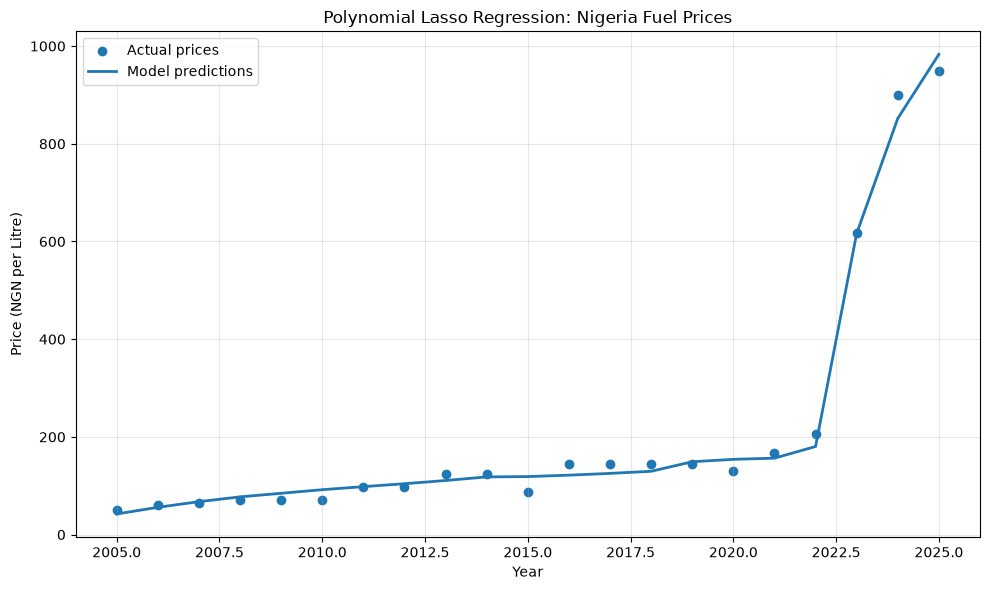

In [29]:

all_predictions = model.predict(X)

plot_df = pd.DataFrame({
    "Year": original_years.to_numpy(),
    "Actual": y.to_numpy(),
    "Predicted": all_predictions
})

plot_df = plot_df.sort_values("Year")

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["Year"],
    plot_df["Actual"],
    label="Actual prices"
)

plt.plot(
    plot_df["Year"],
    plot_df["Predicted"],
    linewidth=2,
    label="Model predictions"
)

plt.title(
    "Polynomial Lasso Regression: Nigeria Fuel Prices"
)

plt.xlabel("Year")
plt.ylabel("Price (NGN per Litre)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


Cell 14 — Visualize MAE comparison

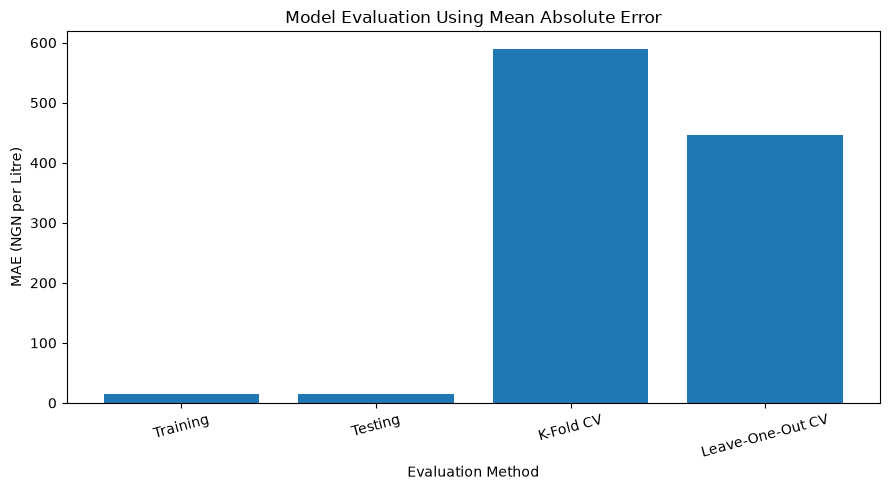

In [30]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Evaluation"],
    comparison["MAE"]
)

plt.title(
    "Model Evaluation Using Mean Absolute Error"
)

plt.xlabel("Evaluation Method")
plt.ylabel("MAE (NGN per Litre)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Cell 15 — Collect user inputs and predict fuel price

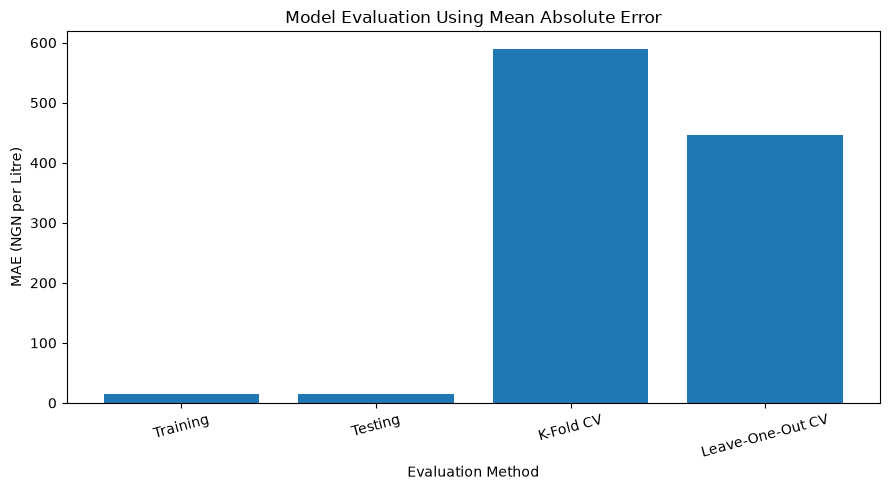

In [31]:

plt.figure(figsize=(9, 5))

plt.bar(
    comparison["Evaluation"],
    comparison["MAE"]
)

plt.title(
    "Model Evaluation Using Mean Absolute Error"
)

plt.xlabel("Evaluation Method")
plt.ylabel("MAE (NGN per Litre)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Cell 16 — Visualize the user's predicted fuel price

In [32]:

# ============================================
# 15. INTERACTIVE FUEL PRICE PREDICTION
# ============================================

print("\n===== FUEL PRICE PREDICTION =====")

user_data = {}

# ============================================
# ENTER PREDICTION YEAR
# ============================================

prediction_year = int(
    input("Enter the year you want to predict: ")
)

# Apply the same year centering as training
user_data["Year"] = prediction_year - base_year


# ============================================
# ENTER NUMERICAL FEATURES
# ============================================

print("\n===== NUMERICAL FEATURES =====")

for feature in numeric_features:

    if feature == "Year":
        continue

    value = input(
        f"Enter {feature} (or press Enter if unknown): "
    ).strip()

    if value == "":
        user_data[feature] = np.nan
    else:
        user_data[feature] = float(value)


# ============================================
# ENTER CATEGORICAL FEATURES
# ============================================

if categorical_features:

    print("\n===== CATEGORICAL FEATURES =====")

    for feature in categorical_features:

        categories = (
            X[feature]
            .dropna()
            .unique()
            .tolist()
        )

        print(
            f"\nAvailable values for {feature}:",
            categories
        )

        value = input(
            f"Enter {feature} (or press Enter if unknown): "
        ).strip()

        if value == "":
            user_data[feature] = np.nan
        else:
            user_data[feature] = value


# ============================================
# CREATE PREDICTION DATAFRAME
# ============================================

future_data = pd.DataFrame([user_data])

# Match training features and their order
future_data = future_data.reindex(
    columns=X.columns
)


# ============================================
# MAKE PREDICTION
# ============================================

predicted_price = model.predict(future_data)


# ============================================
# DISPLAY RESULTS
# ============================================

print("\n===== PREDICTION RESULTS =====")

print(f"\nPrediction Year: {prediction_year}")

print("\nFeature Values:")

display_data = future_data.copy()

# Show the original year instead of centered year
display_data["Year"] = prediction_year

display(display_data)

print(
    f"\nPredicted Fuel Price for {prediction_year}: "
    f"NGN {predicted_price[0]:,.2f} per litre"
)



===== FUEL PRICE PREDICTION =====



===== NUMERICAL FEATURES =====

===== PREDICTION RESULTS =====

Prediction Year: 2027

Feature Values:


,Year,Crude_Oil_USD,Subsidy_NGN_Billion,FX_NGN_per_USD,Import_Duty_Pct,VAT_Pct
0,2027,100.0,0.0,1450.0,5.0,7.5



Predicted Fuel Price for 2027: NGN 781.53 per litre


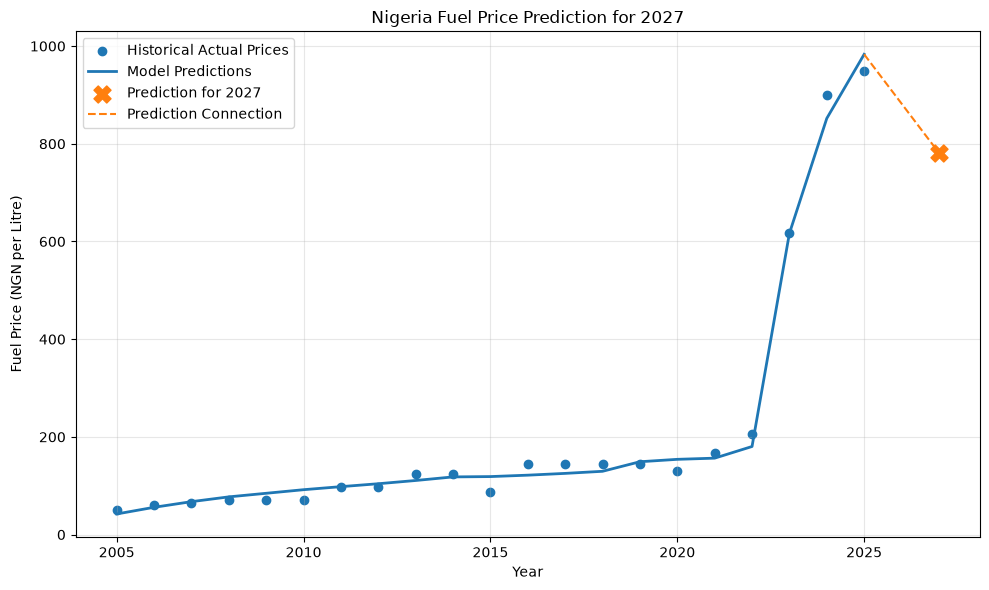

In [33]:

plt.figure(figsize=(10, 6))

# Historical actual prices
plt.scatter(
    original_years,
    y,
    label="Historical Actual Prices"
)

# Historical model predictions
plt.plot(
    plot_df["Year"],
    plot_df["Predicted"],
    linewidth=2,
    label="Model Predictions"
)

# User's prediction
plt.scatter(
    [prediction_year],
    [predicted_price[0]],
    s=150,
    marker="X",
    label=f"Prediction for {prediction_year}",
    zorder=5
)

# Draw a dashed line connecting the latest
# historical prediction to the future prediction
latest_row = plot_df.iloc[-1]

plt.plot(
    [latest_row["Year"], prediction_year],
    [latest_row["Predicted"], predicted_price[0]],
    linestyle="--",
    label="Prediction Connection"
)

plt.title(
    f"Nigeria Fuel Price Prediction for {prediction_year}"
)

plt.xlabel("Year")
plt.ylabel("Fuel Price (NGN per Litre)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
